In [2]:
import pandas as pd 

In [14]:
import pandas as pd
df=pd.read_csv("healthcare-dataset-stroke-data.csv")
df

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [15]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [16]:
df.shape 


(5110, 12)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [18]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [19]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [20]:
df.isnull().sum()


id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [21]:
df['stroke'].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [22]:
# Step 1: flag missing BMI before filling
df['bmi_missing'] = df['bmi'].isnull().astype(int)

# Step 2: KNN imputation
from sklearn.impute import KNNImputer
imputer = KNNImputer(n_neighbors=5)
df[['age', 'avg_glucose_level', 'bmi']] = imputer.fit_transform(df[['age', 'avg_glucose_level', 'bmi']])

# Step 3: confirm no more missing values
df.isnull().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
bmi_missing          0
dtype: int64

In [23]:
df['smoking_status'].value_counts()

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64

In [24]:
df.groupby('smoking_status')['age'].describe()

,count,mean,std,min,25%,50%,75%,max
smoking_status,,,,,,,,
Unknown,1544.0,30.229922,25.055556,0.08,8.0,23.0,51.0,82.0
formerly smoked,885.0,54.929944,17.641723,10.00,43.0,57.0,69.0,82.0
never smoked,1892.0,46.744715,19.769584,10.00,31.0,47.0,62.0,82.0
smokes,789.0,47.096324,16.413002,10.00,33.0,47.0,59.0,82.0


C:\Users\user\AppData\Local\Temp\ipykernel_1768\2228427235.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stroke_by_age = df.groupby('age_group')['stroke'].mean()


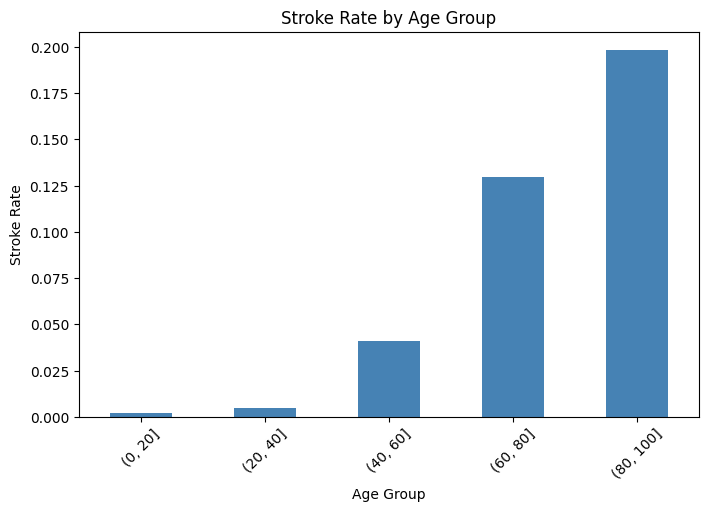

<Figure size 640x480 with 0 Axes>

In [25]:
df['age_group'] = pd.cut(df['age'], bins=[0,20,40,60,80,100])
stroke_by_age = df.groupby('age_group')['stroke'].mean()

stroke_by_age.plot(kind='bar', figsize=(8,5), color='steelblue')
plt.xlabel('Age Group')
plt.ylabel('Stroke Rate')
plt.title('Stroke Rate by Age Group')
plt.xticks(rotation=45)
plt.show()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')

In [26]:
import matplotlib.pyplot as plt

C:\Users\user\AppData\Local\Temp\ipykernel_1768\2228427235.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stroke_by_age = df.groupby('age_group')['stroke'].mean()


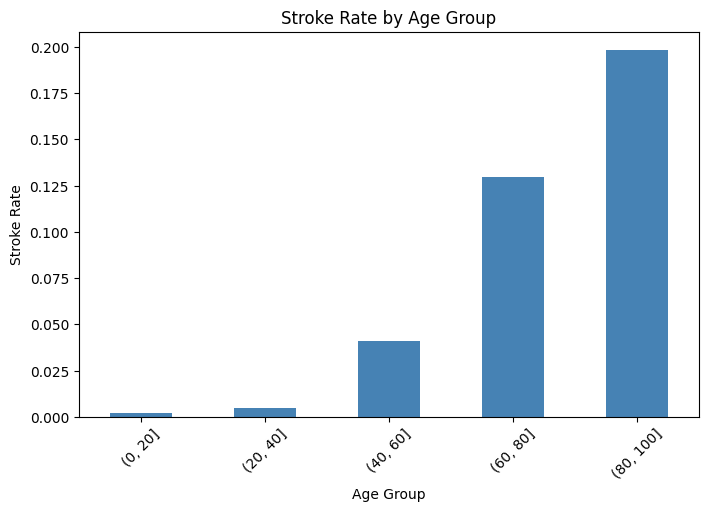

<Figure size 640x480 with 0 Axes>

In [27]:
df['age_group'] = pd.cut(df['age'], bins=[0,20,40,60,80,100])
stroke_by_age = df.groupby('age_group')['stroke'].mean()

stroke_by_age.plot(kind='bar', figsize=(8,5), color='steelblue')
plt.xlabel('Age Group')
plt.ylabel('Stroke Rate')
plt.title('Stroke Rate by Age Group')
plt.xticks(rotation=45)
plt.show()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')

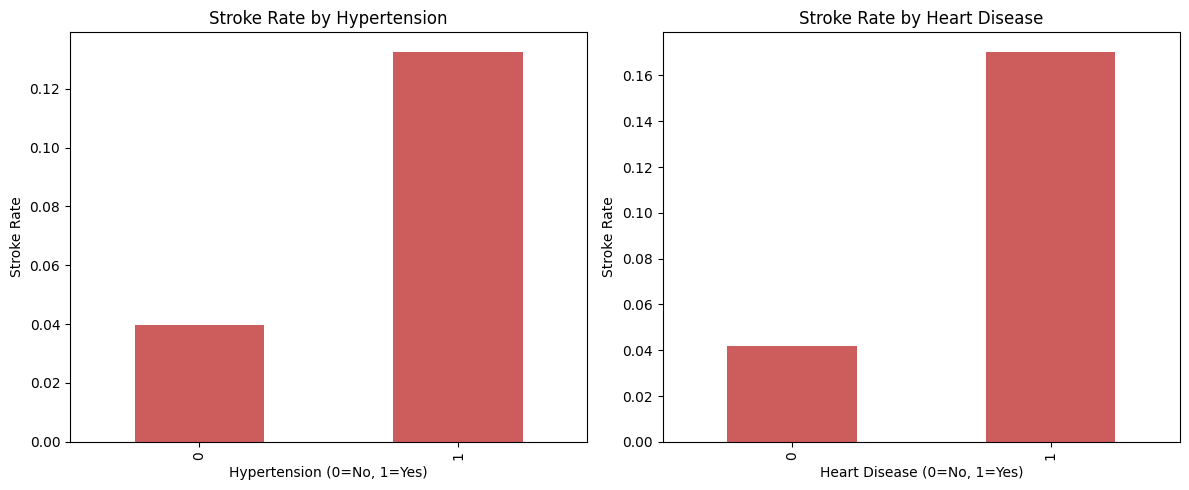

<Figure size 640x480 with 0 Axes>

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

df.groupby('hypertension')['stroke'].mean().plot(kind='bar', ax=axes[0], color='indianred')
axes[0].set_title('Stroke Rate by Hypertension')
axes[0].set_xlabel('Hypertension (0=No, 1=Yes)')
axes[0].set_ylabel('Stroke Rate')

df.groupby('heart_disease')['stroke'].mean().plot(kind='bar', ax=axes[1], color='indianred')
axes[1].set_title('Stroke Rate by Heart Disease')
axes[1].set_xlabel('Heart Disease (0=No, 1=Yes)')
axes[1].set_ylabel('Stroke Rate')

plt.tight_layout()
plt.show()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')

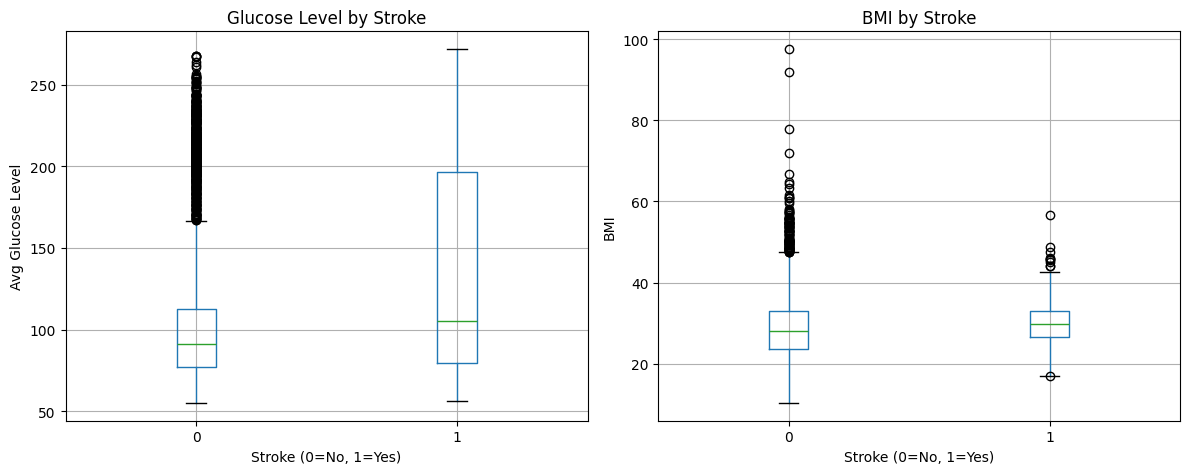

<Figure size 640x480 with 0 Axes>

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

df.boxplot(column='avg_glucose_level', by='stroke', ax=axes[0])
axes[0].set_title('Glucose Level by Stroke')
axes[0].set_xlabel('Stroke (0=No, 1=Yes)')
axes[0].set_ylabel('Avg Glucose Level')

df.boxplot(column='bmi', by='stroke', ax=axes[1])
axes[1].set_title('BMI by Stroke')
axes[1].set_xlabel('Stroke (0=No, 1=Yes)')
axes[1].set_ylabel('BMI')

plt.suptitle('')  # removes the default automatic title
plt.tight_layout()
plt.show()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')

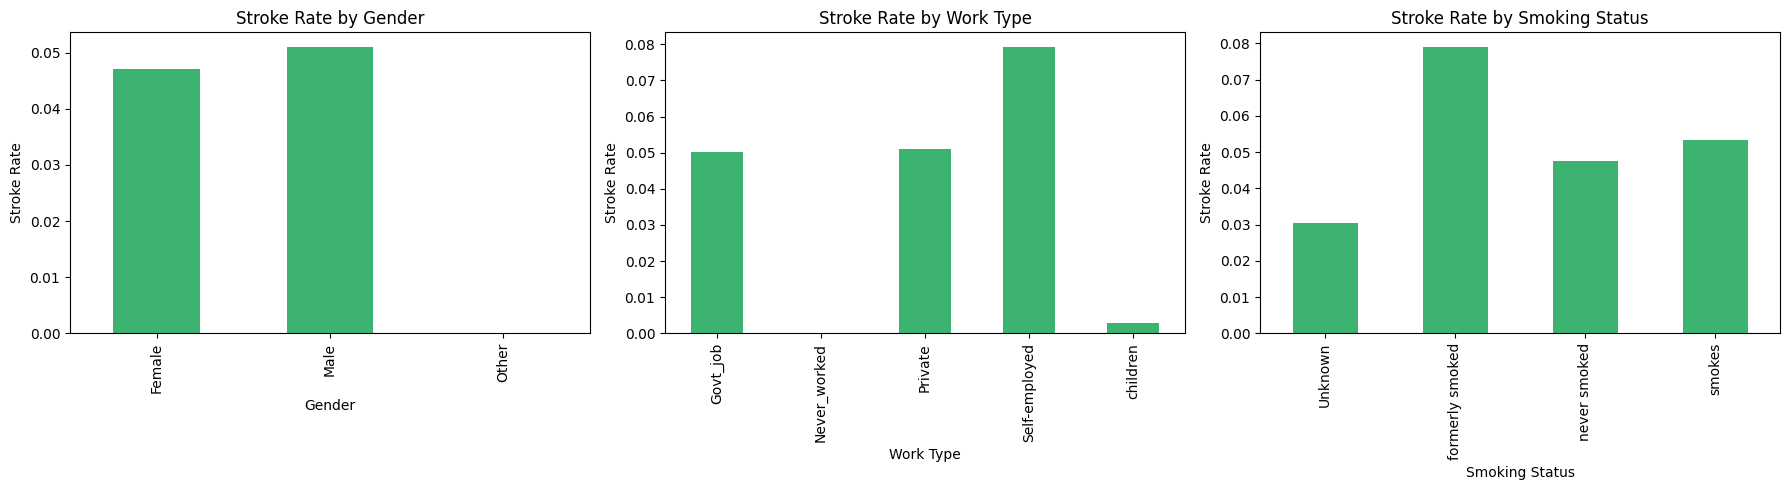

<Figure size 640x480 with 0 Axes>

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))

df.groupby('gender')['stroke'].mean().plot(kind='bar', ax=axes[0], color='mediumseagreen')
axes[0].set_title('Stroke Rate by Gender')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Stroke Rate')

df.groupby('work_type')['stroke'].mean().plot(kind='bar', ax=axes[1], color='mediumseagreen')
axes[1].set_title('Stroke Rate by Work Type')
axes[1].set_xlabel('Work Type')
axes[1].set_ylabel('Stroke Rate')

df.groupby('smoking_status')['stroke'].mean().plot(kind='bar', ax=axes[2], color='mediumseagreen')
axes[2].set_title('Stroke Rate by Smoking Status')
axes[2].set_xlabel('Smoking Status')
axes[2].set_ylabel('Stroke Rate')

plt.tight_layout()
plt.show()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')

In [32]:
df.groupby('work_type')['age'].mean()


work_type
Govt_job         50.879756
Never_worked     16.181818
Private          45.503932
Self-employed    60.201465
children          6.841339
Name: age, dtype: float64

In [33]:
df = df.drop(columns=['id', 'age_group'])

In [34]:
df_encoded = pd.get_dummies(df, columns=['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status'], drop_first=True)

In [35]:
df_encoded.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,bmi_missing,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.60,1,0,True,False,True,False,True,False,False,True,True,False,False
1,61.0,0,0,202.21,31.38,1,1,False,False,True,False,False,True,False,False,False,True,False
2,80.0,0,1,105.92,32.50,1,0,True,False,True,False,True,False,False,False,False,True,False
3,49.0,0,0,171.23,34.40,1,0,False,False,True,False,True,False,False,True,False,False,True
4,79.0,1,0,174.12,24.00,1,0,False,False,True,False,False,True,False,False,False,True,False


In [36]:
X = df_encoded.drop(columns=['stroke'])
y = df_encoded['stroke']

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(4088, 17) (1022, 17)


In [38]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_resampled.value_counts())

stroke
0    3889
1     199
Name: count, dtype: int64
stroke
0    3889
1    3889
Name: count, dtype: int64


In [39]:
!pip install imbalanced-learn


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_resampled.value_counts())

stroke
0    3889
1     199
Name: count, dtype: int64
stroke
0    3889
1    3889
Name: count, dtype: int64


In [41]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_resampled, y_train_resampled)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [42]:
y_pred = model.predict(X_test)

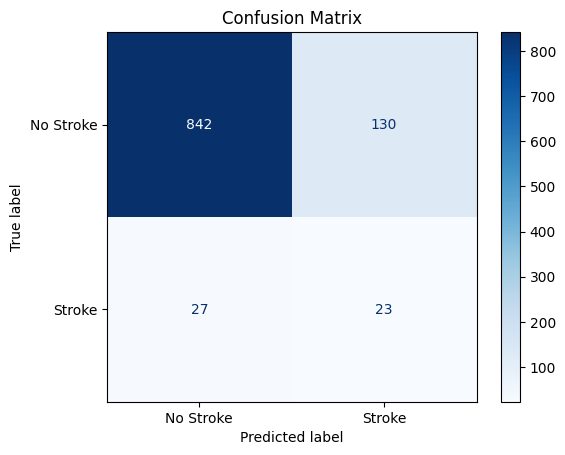

<Figure size 640x480 with 0 Axes>

In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Stroke', 'Stroke'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')

In [44]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.87      0.91       972
           1       0.15      0.46      0.23        50

    accuracy                           0.85      1022
   macro avg       0.56      0.66      0.57      1022
weighted avg       0.93      0.85      0.88      1022



In [46]:
from sklearn.metrics import roc_auc_score

y_pred_proba = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {auc:.3f}")

ROC-AUC Score: 0.789


In [47]:
# Try a lower threshold instead of the default 0.5
threshold = 0.3
y_pred_adjusted = (y_pred_proba >= threshold).astype(int)

print(classification_report(y_test, y_pred_adjusted))

              precision    recall  f1-score   support

           0       0.98      0.76      0.86       972
           1       0.13      0.68      0.21        50

    accuracy                           0.76      1022
   macro avg       0.55      0.72      0.53      1022
weighted avg       0.94      0.76      0.82      1022



In [48]:
threshold = 0.2
y_pred_adjusted = (y_pred_proba >= threshold).astype(int)
print(classification_report(y_test, y_pred_adjusted))

              precision    recall  f1-score   support

           0       0.98      0.70      0.82       972
           1       0.11      0.70      0.19        50

    accuracy                           0.70      1022
   macro avg       0.54      0.70      0.50      1022
weighted avg       0.94      0.70      0.79      1022



In [49]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
rf_model.fit(X_train_resampled, y_train_resampled)

rf_pred_proba = rf_model.predict_proba(X_test)[:, 1]
rf_pred = rf_model.predict(X_test)

print(classification_report(y_test, rf_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, rf_pred_proba):.3f}")

              precision    recall  f1-score   support

           0       0.96      0.96      0.96       972
           1       0.14      0.14      0.14        50

    accuracy                           0.92      1022
   macro avg       0.55      0.55      0.55      1022
weighted avg       0.92      0.92      0.92      1022

ROC-AUC Score: 0.783


In [50]:
threshold = 0.3
rf_pred_adjusted = (rf_pred_proba >= threshold).astype(int)
print(classification_report(y_test, rf_pred_adjusted))

              precision    recall  f1-score   support

           0       0.96      0.89      0.93       972
           1       0.14      0.34      0.20        50

    accuracy                           0.86      1022
   macro avg       0.55      0.62      0.56      1022
weighted avg       0.92      0.86      0.89      1022



In [51]:
import numpy as np

coefficients = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': model.coef_[0]
}).sort_values('coefficient', ascending=False)

print(coefficients)

                           feature  coefficient
12              work_type_children     4.228285
16           smoking_status_smokes     2.614062
10               work_type_Private     2.505410
14  smoking_status_formerly smoked     2.395704
15     smoking_status_never smoked     2.391528
11         work_type_Self-employed     2.120464
13            Residence_type_Urban     1.265523
8                 ever_married_Yes     1.220850
6                      gender_Male     0.933658
5                      bmi_missing     0.907468
0                              age     0.083369
3                avg_glucose_level     0.004649
4                              bmi    -0.009657
7                     gender_Other    -0.017712
9           work_type_Never_worked    -0.072829
2                    heart_disease    -0.777903
1                     hypertension    -0.921533


In [52]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Redo SMOTE on the scaled data
X_train_resampled_scaled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# Retrain logistic regression
model_scaled = LogisticRegression(max_iter=1000, random_state=42)
model_scaled.fit(X_train_resampled_scaled, y_train_resampled)

# Check coefficients again
coefficients_scaled = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': model_scaled.coef_[0]
}).sort_values('coefficient', ascending=False)

print(coefficients_scaled)

                           feature  coefficient
0                              age     2.080384
12              work_type_children     0.365633
5                      bmi_missing     0.309615
16           smoking_status_smokes     0.199608
3                avg_glucose_level     0.198758
1                     hypertension     0.195640
14  smoking_status_formerly smoked     0.100284
10               work_type_Private     0.069804
15     smoking_status_never smoked     0.054456
2                    heart_disease     0.051736
8                 ever_married_Yes     0.047003
13            Residence_type_Urban     0.020373
7                     gender_Other    -0.043778
4                              bmi    -0.054107
9           work_type_Never_worked    -0.086525
6                      gender_Male    -0.097481
11         work_type_Self-employed    -0.147003


In [53]:
y_pred_proba_scaled = model_scaled.predict_proba(X_test_scaled)[:, 1]

threshold = 0.3
y_pred_scaled_adjusted = (y_pred_proba_scaled >= threshold).astype(int)

print(classification_report(y_test, y_pred_scaled_adjusted))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_scaled):.3f}")

              precision    recall  f1-score   support

           0       0.99      0.64      0.77       972
           1       0.11      0.86      0.19        50

    accuracy                           0.65      1022
   macro avg       0.55      0.75      0.48      1022
weighted avg       0.95      0.65      0.75      1022

ROC-AUC Score: 0.844


In [54]:
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (y_pred_proba_scaled >= t).astype(int)
    print(f"--- Threshold {t} ---")
    print(classification_report(y_test, pred, digits=2))

--- Threshold 0.3 ---
              precision    recall  f1-score   support

           0       0.99      0.64      0.77       972
           1       0.11      0.86      0.19        50

    accuracy                           0.65      1022
   macro avg       0.55      0.75      0.48      1022
weighted avg       0.95      0.65      0.75      1022

--- Threshold 0.4 ---
              precision    recall  f1-score   support

           0       0.99      0.70      0.82       972
           1       0.12      0.82      0.22        50

    accuracy                           0.71      1022
   macro avg       0.56      0.76      0.52      1022
weighted avg       0.94      0.71      0.79      1022

--- Threshold 0.5 ---
              precision    recall  f1-score   support

           0       0.99      0.76      0.86       972
           1       0.14      0.78      0.24        50

    accuracy                           0.76      1022
   macro avg       0.56      0.77      0.55      1022
weighted

=== FINAL MODEL: Logistic Regression (Scaled + SMOTE) ===
Threshold: 0.6
              precision    recall  f1-score   support

           0       0.98      0.81      0.89       972
           1       0.17      0.74      0.27        50

    accuracy                           0.81      1022
   macro avg       0.57      0.77      0.58      1022
weighted avg       0.94      0.81      0.86      1022

ROC-AUC Score: 0.844


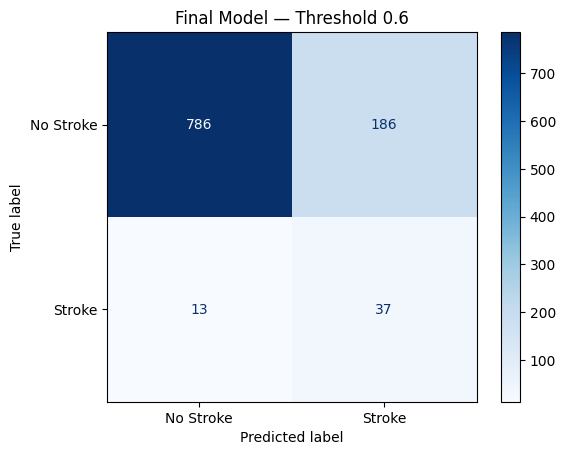

<Figure size 640x480 with 0 Axes>

In [55]:
FINAL_THRESHOLD = 0.6

y_pred_final = (y_pred_proba_scaled >= FINAL_THRESHOLD).astype(int)

print("=== FINAL MODEL: Logistic Regression (Scaled + SMOTE) ===")
print(f"Threshold: {FINAL_THRESHOLD}")
print(classification_report(y_test, y_pred_final))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_scaled):.3f}")

cm_final = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=['No Stroke', 'Stroke'])
disp.plot(cmap='Blues')
plt.title(f'Final Model — Threshold {FINAL_THRESHOLD}')
plt.show()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')

# Stroke Prediction — Summary & Conclusion

## Objective
Predict stroke risk from patient health and demographic data, with a focus 
on identifying at-risk individuals (high recall) given the clinical cost 
of missed cases.

## Data
- Source: Kaggle Stroke Prediction Dataset (5,110 patients, 12 features)
- Missing values: ~4% of BMI values, imputed using KNN imputation; a 
  `bmi_missing` flag was retained
- `smoking_status` contained ~30% "Unknown" values, largely explained by 
  young patients (median age ~23) who were never asked — kept as its own 
  category rather than imputed

## Key EDA Findings
- **Age** is the strongest predictor: stroke rate rises from ~0.2% (under 20) 
  to ~20% (80+)
- **Hypertension** and **heart disease** roughly triple/quadruple stroke risk
- **Glucose level** shows a moderate positive relationship with stroke
- **BMI** shows little independent relationship with stroke
- **Work type** appeared predictive but was found to be confounded by age 
  (e.g., self-employed patients average 60 years old vs. 6.8 for children)

## Modeling Approach
- Class imbalance (95% no-stroke / 5% stroke) addressed using SMOTE on the 
  training set only
- Compared Logistic Regression vs. Random Forest — both showed similar AUC 
  (~0.78-0.79), but Logistic Regression achieved much higher recall at 
  matched thresholds
- Discovered and corrected a feature-scaling issue: unscaled logistic 
  regression produced coefficients that contradicted EDA (e.g., hypertension 
  appearing "protective"); applying StandardScaler fixed this and improved 
  AUC from 0.789 to 0.844
- Performed a threshold sweep (0.3-0.7) to balance recall against precision 
  and accuracy, since the default 0.5 threshold is not well-suited to 
  imbalanced classification

## Final Model
**Logistic Regression, scaled features, SMOTE-balanced training, threshold = 0.6**
- ROC-AUC: 0.844
- Recall (stroke): 0.76
- Precision (stroke): 0.17
- Accuracy: 0.81

## Interpretation
Top predictors (by scaled coefficient): age, average glucose level, 
hypertension, smoking status. These align with established clinical risk 
factors for stroke, supporting the model's validity beyond pure statistical fit.

## Limitations
- Precision remains low — in a real deployment, this model would need to 
  function as a *screening* tool (flagging patients for further review), 
  not a diagnostic one
- SMOTE-generated synthetic data may not perfectly reflect real patient 
  distributions, especially for categorical features
- Dataset is relatively small (5,110 rows); results may not generalize to 
  broader populations without further validation

## Possible Next Steps
- Try XGBoost or gradient boosting with proper hyperparameter tuning
- Explore cost-sensitive learning instead of SMOTE
- Validate on an external stroke dataset

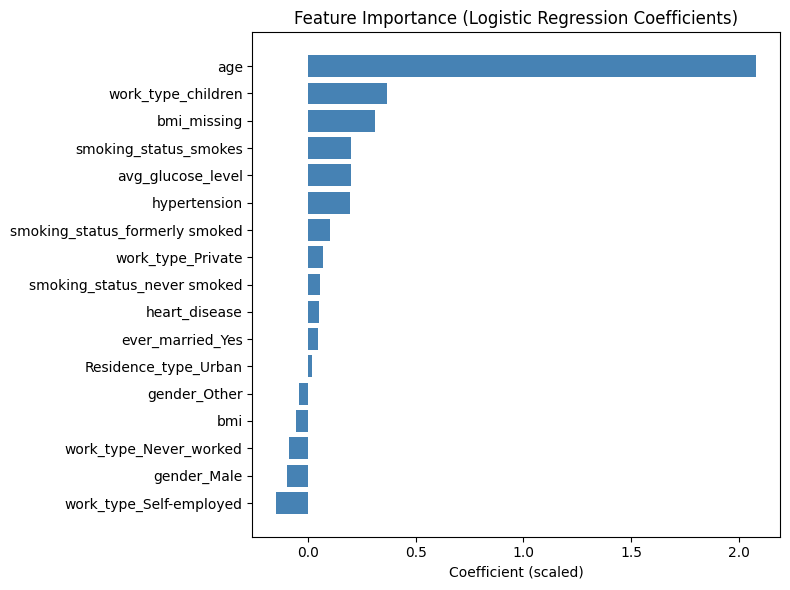

<Figure size 640x480 with 0 Axes>

In [56]:
import matplotlib.pyplot as plt

coef_sorted = coefficients_scaled.sort_values('coefficient')
plt.figure(figsize=(8,6))
plt.barh(coef_sorted['feature'], coef_sorted['coefficient'], color='steelblue')
plt.title('Feature Importance (Logistic Regression Coefficients)')
plt.xlabel('Coefficient (scaled)')
plt.tight_layout()
plt.show()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')

In [1]:
import os
print(os.getcwd())

c:\Users\user\Desktop\stroke-project
